In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

print("Evaluation libraries loaded.")

Evaluation libraries loaded.


In [2]:
df = pd.read_csv("../data/ai4i2020.csv")

df = df.rename(columns={
    "UDI": "udi",
    "Product ID": "product_id",
    "Type": "type",
    "Air temperature [K]": "air_temperature",
    "Process temperature [K]": "process_temperature",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "machine_failure"
})

df["temperature_difference"] = (
    df["process_temperature"] - df["air_temperature"]
)

df["mechanical_power"] = (
    df["torque"] * df["rotational_speed"] * (2 * np.pi / 60)
)

df["wear_torque_interaction"] = (
    df["tool_wear"] * df["torque"]
)

features = [
    "type",
    "air_temperature",
    "process_temperature",
    "rotational_speed",
    "torque",
    "tool_wear",
    "temperature_difference",
    "mechanical_power",
    "wear_torque_interaction"
]

X = df[features]
y = df["machine_failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Failure distribution in test data:")
print(y_test.value_counts())

Training samples: 8000
Testing samples: 2000
Failure distribution in test data:
machine_failure
0    1932
1      68
Name: count, dtype: int64


In [3]:
logistic_model = joblib.load(
    "../models/logistic_regression_pipeline.joblib"
)

pca_artifact = joblib.load(
    "../models/pca_pipeline.joblib"
)

rf_artifact = joblib.load(
    "../models/random_forest_pipeline.joblib"
)

print("All three model artifacts loaded.")

All three model artifacts loaded.


In [4]:
# Logistic Regression
logistic_predictions = logistic_model.predict(X_test)

logistic_probabilities = (
    logistic_model.predict_proba(X_test)[:, 1]
)


# PCA + Logistic Regression
X_test_pca_processed = pca_artifact["preprocessor"].transform(X_test)

X_test_pca = pca_artifact["pca"].transform(
    X_test_pca_processed
)

pca_model = pca_artifact["model"]

pca_predictions = pca_model.predict(X_test_pca)

pca_probabilities = pca_model.predict_proba(
    X_test_pca
)[:, 1]


# Random Forest
X_test_rf = rf_artifact["preprocessor"].transform(X_test)

rf_model = rf_artifact["model"]

rf_predictions = rf_model.predict(X_test_rf)

rf_probabilities = rf_model.predict_proba(
    X_test_rf
)[:, 1]

print("Predictions generated for all three models.")

Predictions generated for all three models.


In [5]:
def calculate_metrics(y_true, predictions, probabilities):

    return {
        "Accuracy": accuracy_score(y_true, predictions),

        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),

        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),

        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }

In [6]:
model_comparison = pd.DataFrame({
    "Logistic Regression": calculate_metrics(
        y_test,
        logistic_predictions,
        logistic_probabilities
    ),

    "Logistic Regression + PCA": calculate_metrics(
        y_test,
        pca_predictions,
        pca_probabilities
    ),

    "Random Forest": calculate_metrics(
        y_test,
        rf_predictions,
        rf_probabilities
    )
}).T

display(model_comparison.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.8585,0.1791,0.8824,0.2978,0.9385,0.4297
Logistic Regression + PCA,0.7245,0.0927,0.8088,0.1664,0.8115,0.1808
Random Forest,0.9915,0.9474,0.7941,0.8640,0.9822,0.8811


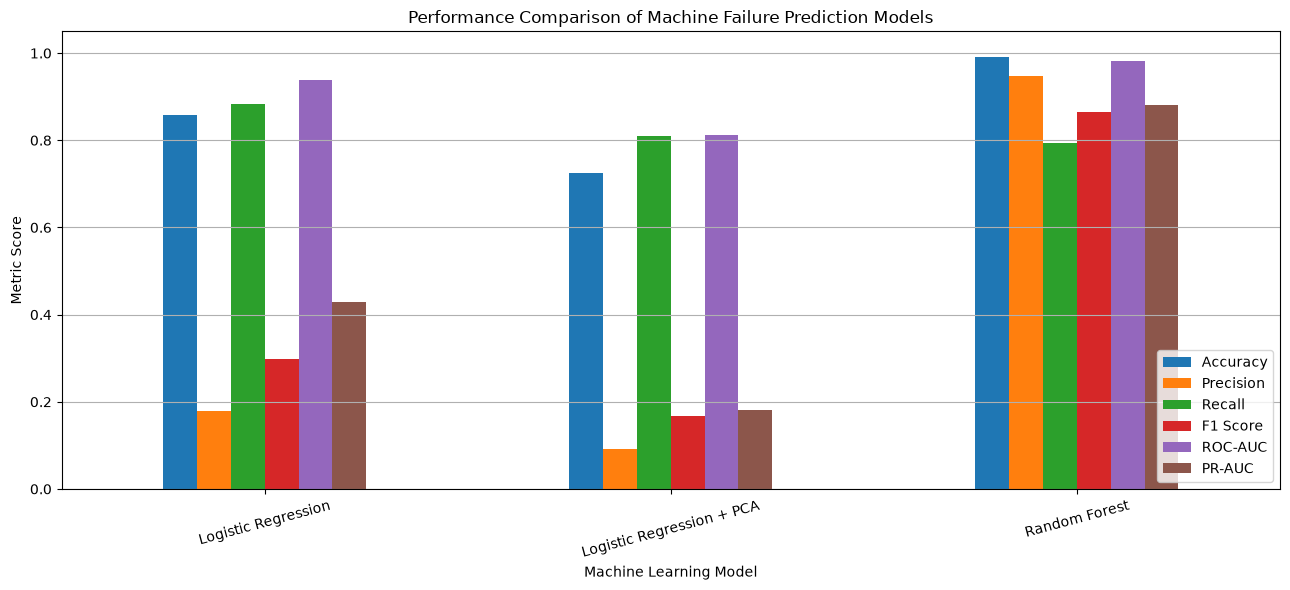

In [7]:
model_comparison.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Performance Comparison of Machine Failure Prediction Models")
plt.ylabel("Metric Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

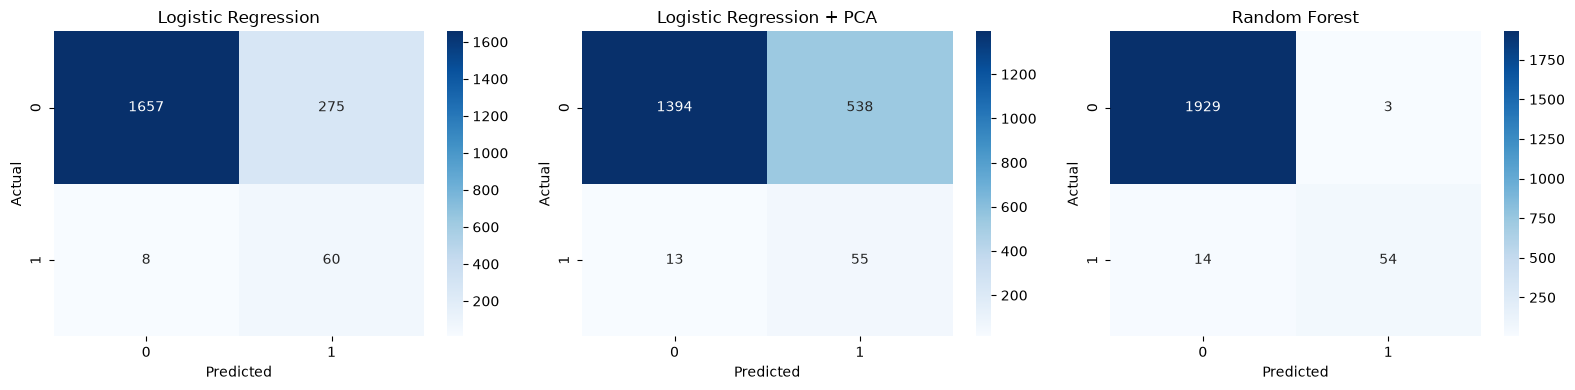

In [8]:
predictions = {
    "Logistic Regression": logistic_predictions,
    "Logistic Regression + PCA": pca_predictions,
    "Random Forest": rf_predictions
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, prediction) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, prediction)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

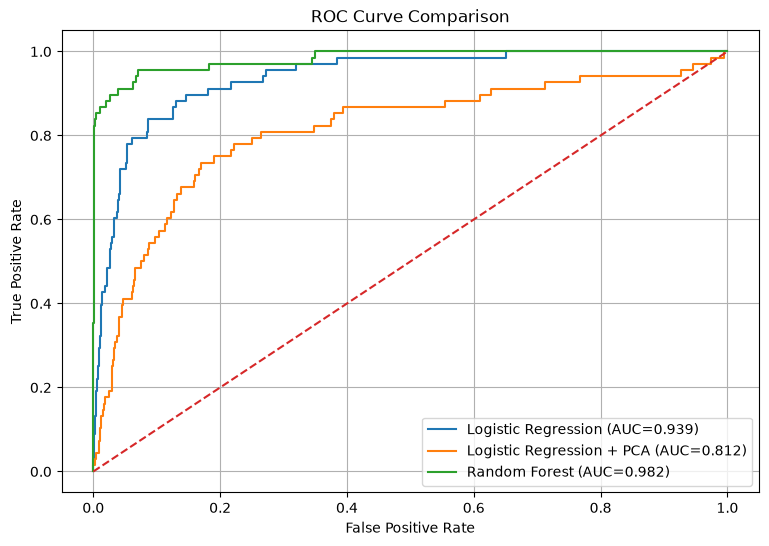

In [9]:
probability_outputs = {
    "Logistic Regression": logistic_probabilities,
    "Logistic Regression + PCA": pca_probabilities,
    "Random Forest": rf_probabilities
}

plt.figure(figsize=(9, 6))

for name, probabilities in probability_outputs.items():

    fpr, tpr, _ = roc_curve(y_test, probabilities)

    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.show()

In [10]:
best_model = model_comparison["PR-AUC"].idxmax()

print("Highest PR-AUC:", best_model)

print("\nComplete model comparison:")
display(model_comparison.round(4))

Highest PR-AUC: Random Forest

Complete model comparison:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.8585,0.1791,0.8824,0.2978,0.9385,0.4297
Logistic Regression + PCA,0.7245,0.0927,0.8088,0.1664,0.8115,0.1808
Random Forest,0.9915,0.9474,0.7941,0.8640,0.9822,0.8811


In [11]:
os.makedirs("../results/metrics", exist_ok=True)
os.makedirs("../results/predictions", exist_ok=True)

model_comparison.to_csv(
    "../results/metrics/final_model_comparison.csv"
)

all_predictions = pd.DataFrame({
    "actual_failure": y_test.values,

    "logistic_prediction": logistic_predictions,
    "logistic_probability": logistic_probabilities,

    "pca_prediction": pca_predictions,
    "pca_probability": pca_probabilities,

    "rf_prediction": rf_predictions,
    "rf_probability": rf_probabilities
})

all_predictions.to_csv(
    "../results/predictions/final_model_predictions.csv",
    index=False
)

print("Model evaluation results saved.")

Model evaluation results saved.
